# Feature Preparation

inner fitness split, pca to 32 fitted on train, angles in 0 to pi, then how much signal the components carry on val. 

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

seed = 0
np.random.seed(seed)

data_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-clip-dataset/features"
out_dir = "/kaggle/working/prep"
os.makedirs(out_dir, exist_ok=True)

n_inner = 54            # about 15% of the 360 train pairs
n_components = 32
low, high = 0.5, 99.5   # angle range from train percentiles, so a few extreme frames don't squeeze the rest
names = ["ffpp_train", "ffpp_val", "ffpp_test", "celebdf_test"]

In [2]:
clip, meta = {}, {}
for name in names:
    clip[name] = np.load(f"{data_dir}/{name}_clip.npy")
    meta[name] = pd.read_csv(f"{data_dir}/{name}_rows.csv")
    print(name, clip[name].shape, "real", (meta[name]["label"] == 0).sum(), "fake", (meta[name]["label"] == 1).sum())

ffpp_train (46076, 512) real 23039 fake 23037
ffpp_val (22396, 512) real 4480 fake 17916
ffpp_test (22400, 512) real 4480 fake 17920
celebdf_test (16572, 512) real 5692 fake 10880


## inner fitness split

a fake is named after its pair (000_003 comes from originals 000 and 003), so every real video can be put back in its pair and both people of a pair stay on the same side.

In [3]:
def pair_of(video_id):
    a, b = video_id.split("_")
    return tuple(sorted([a, b]))


train = meta["ffpp_train"]
pairs = sorted(set(pair_of(v) for v in train.loc[train["label"] == 1, "video_id"]))
print("train pairs:", len(pairs), "(expected 360)")

real_pair = {}
for a, b in pairs:
    real_pair[a] = (a, b)
    real_pair[b] = (a, b)

train_pair = [real_pair[v] if m == "original" else pair_of(v) for m, v in zip(train["method"], train["video_id"])]

rng = np.random.default_rng(seed)
inner = set(pairs[i] for i in rng.choice(len(pairs), size=n_inner, replace=False))
is_inner = np.array([p in inner for p in train_pair])

with open(f"{out_dir}/ffpp_inner_fitness.json", "w") as f:
    json.dump({"seed": seed, "n_pairs": n_inner, "pairs": sorted([list(p) for p in inner])}, f, indent=1)

print("search-train frames:", (~is_inner).sum(), "(expected 39164)")
print("inner fitness frames:", is_inner.sum(), "(expected 6912)")
print("inner fitness videos:", train[is_inner].groupby(["method", "video_id"]).ngroups, "(expected 540)")

train pairs: 360 (expected 360)
search-train frames: 39164 (expected 39164)
inner fitness frames: 6912 (expected 6912)
inner fitness videos: 540 (expected 540)


## pca and angles

each clip vector is scaled to length 1, pca and the angle range are fitted on train only and applied to the rest.

In [4]:
xn = {name: clip[name] / np.linalg.norm(clip[name], axis=1, keepdims=True) for name in names}

pca = PCA(n_components=n_components, svd_solver="full")
pca.fit(xn["ffpp_train"])
z = {name: pca.transform(xn[name]) for name in names}

lo = np.percentile(z["ffpp_train"], low, axis=0)
hi = np.percentile(z["ffpp_train"], high, axis=0)
angles = {name: np.clip((z[name] - lo) / (hi - lo), 0.0, 1.0) * np.pi for name in names}

for name in names:
    np.save(f"{out_dir}/{name}_pca32.npy", z[name].astype(np.float32))
    np.save(f"{out_dir}/{name}_angles32.npy", angles[name].astype(np.float32))
    meta[name].to_csv(f"{out_dir}/{name}_rows.csv", index=False)
np.save(f"{out_dir}/ffpp_train_is_inner.npy", is_inner)
np.savez(f"{out_dir}/pca32_params.npz", components=pca.components_, mean=pca.mean_,
         explained_variance_ratio=pca.explained_variance_ratio_, angle_lo=lo, angle_hi=hi)

cum = np.cumsum(pca.explained_variance_ratio_)
for k in [4, 8, 12, 32]:
    print(f"variance kept by the first {k:2d} components: {100 * cum[k - 1]:.1f}%")

variance kept by the first  4 components: 31.7%
variance kept by the first  8 components: 42.5%
variance kept by the first 12 components: 49.4%
variance kept by the first 32 components: 69.4%


## per-component auc

auc of each component on its own, on search-train and val. a component can be high for fakes or for reals, so the strength is max(auc, 1 - auc).

best 8 on search-train: [2, 3, 4, 8, 10, 16, 17, 21]
of them in the first 8: 3


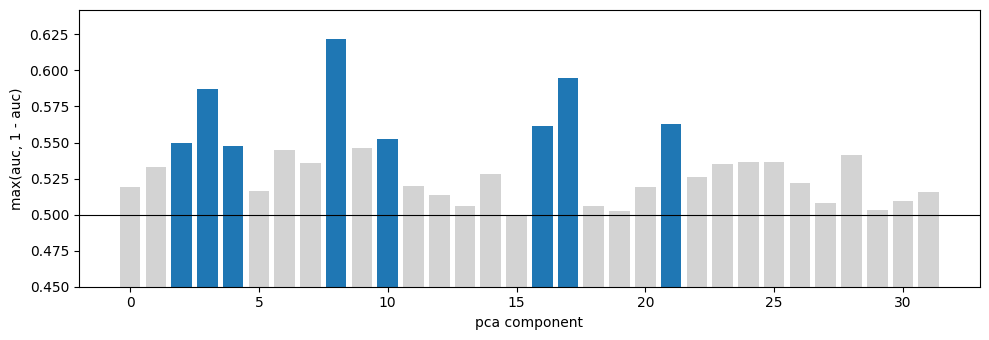

In [5]:
y_train = train["label"].to_numpy()
y_val = meta["ffpp_val"]["label"].to_numpy()
st = ~is_inner

comp = []
for j in range(n_components):
    auc_st = roc_auc_score(y_train[st], z["ffpp_train"][st, j])
    auc_val = roc_auc_score(y_val, z["ffpp_val"][:, j])
    comp.append({"component": j, "variance_pct": 100 * pca.explained_variance_ratio_[j],
                 "auc_search_train": auc_st, "strength_search_train": max(auc_st, 1 - auc_st),
                 "auc_val": auc_val, "strength_val": max(auc_val, 1 - auc_val)})
comp = pd.DataFrame(comp)
comp.to_csv(f"{out_dir}/per_component_auc.csv", index=False)

best8 = comp.sort_values("strength_search_train", ascending=False)["component"].head(8).tolist()
print("best 8 on search-train:", sorted(best8))
print("of them in the first 8:", sum(j < 8 for j in best8))

plt.figure(figsize=(10, 3.5))
plt.bar(comp["component"], comp["strength_search_train"],
        color=["tab:blue" if j in best8 else "lightgray" for j in comp["component"]])
plt.axhline(0.5, color="black", linewidth=0.8)
plt.xlabel("pca component")
plt.ylabel("max(auc, 1 - auc)")
plt.ylim(0.45, comp["strength_search_train"].max() + 0.02)
plt.tight_layout()
plt.savefig(f"{out_dir}/per_component_auc.png", dpi=150)
plt.show()

## logistic regression on val

trained on all of ff++ train, scored on val at frame and video level. a video is (method, video_id) and its score is the mean of its frame probabilities. one fixed setting (standardized, C = 1), a sanity check, not a tuned baseline.

In [6]:
val = meta["ffpp_val"]
val_video = val.groupby(["method", "video_id"]).ngroup().to_numpy()


def video_level(prob):
    df = pd.DataFrame({"video": val_video, "p": prob, "y": y_val})
    g = df.groupby("video").agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


inputs = [
    ("first 4", z["ffpp_train"][:, :4], z["ffpp_val"][:, :4]),
    ("first 8", z["ffpp_train"][:, :8], z["ffpp_val"][:, :8]),
    ("first 12", z["ffpp_train"][:, :12], z["ffpp_val"][:, :12]),
    ("all 32", z["ffpp_train"], z["ffpp_val"]),
    ("best 8", z["ffpp_train"][:, best8], z["ffpp_val"][:, best8]),
    ("512 linear probe", xn["ffpp_train"], xn["ffpp_val"]),
]

table, probs = [], {}
for name, xt, xv in inputs:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))
    model.fit(xt, y_train)
    probs[name] = model.predict_proba(xv)[:, 1]
    pv, yv = video_level(probs[name])
    table.append({"input": name, "frame auc": round(roc_auc_score(y_val, probs[name]), 3),
                  "video auc": round(roc_auc_score(yv, pv), 3)})

table = pd.DataFrame(table)
table.to_csv(f"{out_dir}/bottleneck_check.csv", index=False)
print(table.to_string(index=False))

           input  frame auc  video auc
         first 4      0.600      0.618
         first 8      0.612      0.636
        first 12      0.665      0.689
          all 32      0.731      0.757
          best 8      0.692      0.713
512 linear probe      0.860      0.893


## how precise is one val auc

1000 bootstrap resamples over val videos for the first 8 components.

In [7]:
pv, yv = video_level(probs["first 8"])
rng = np.random.default_rng(seed)
aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(yv), len(yv))
    if yv[idx].min() == yv[idx].max():
        continue
    aucs.append(roc_auc_score(yv[idx], pv[idx]))
lo_ci, hi_ci = np.percentile(aucs, [2.5, 97.5])
print(f"first 8 video auc {roc_auc_score(yv, pv):.3f}, 95% interval {lo_ci:.3f} to {hi_ci:.3f}")

first 8 video auc 0.636, 95% interval 0.586 to 0.683


## val auc per manipulation method

each method's fakes against all real videos, at video level.

In [8]:
video_method = val.groupby(["method", "video_id"])["method"].first().to_numpy()

per_method = []
for name in ["first 8", "512 linear probe"]:
    pv, yv = video_level(probs[name])
    for m in ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]:
        keep = (video_method == "original") | (video_method == m)
        per_method.append({"input": name, "method": m, "video auc": roc_auc_score(yv[keep], pv[keep])})

per_method = pd.DataFrame(per_method)
per_method.to_csv(f"{out_dir}/per_method_auc.csv", index=False)
print(per_method.pivot(index="method", columns="input", values="video auc").round(3).to_string())

input           512 linear probe  first 8
method                                   
Deepfakes                  0.963    0.817
Face2Face                  0.876    0.564
FaceSwap                   0.944    0.687
NeuralTextures             0.786    0.477
